# Lab 9: Classifying Factory Reports with NLP

MLPR, Semester 4. Factory maintenance reports are cleaned (lowercasing, punctuation and stop-word removal), turned into TF-IDF vectors and classified into failure categories with a Random Forest.

In [1]:
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

for pkg in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

df = pd.read_excel("data/factoryReports.xlsx")
print(df.shape)
print(df["Category"].value_counts())
df[["Description", "Category"]].head()

(480, 5)
Category
Mechanical Failure    204
Electronic Failure    168
Leak                   68
Software Failure       40
Name: count, dtype: int64


,Description,Category
0,Items are occasionally getting stuck in the sc...,Mechanical Failure
1,Loud rattling and banging sounds are coming fr...,Mechanical Failure
2,There are cuts to the power when starting the ...,Electronic Failure
3,Fried capacitors in the assembler.,Electronic Failure
4,Mixer tripped the fuses.,Electronic Failure


Model accuracy: 0.917

                    precision    recall  f1-score   support

Electronic Failure       0.90      0.85      0.88        33
              Leak       1.00      0.92      0.96        13
Mechanical Failure       0.89      0.95      0.92        42
  Software Failure       1.00      1.00      1.00         8

          accuracy                           0.92        96
         macro avg       0.95      0.93      0.94        96
      weighted avg       0.92      0.92      0.92        96



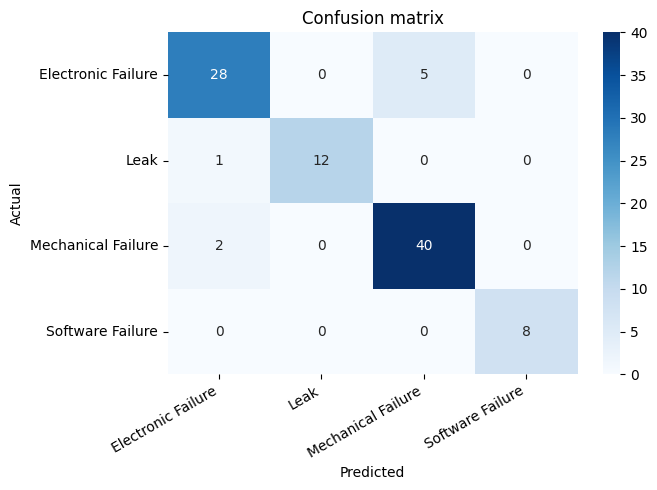

In [2]:
stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    words = word_tokenize(text.lower().translate(str.maketrans("", "", string.punctuation)))
    return " ".join(w for w in words if w not in stop_words)

df["Cleaned_Description"] = df["Description"].apply(preprocess_text)
X = TfidfVectorizer().fit_transform(df["Cleaned_Description"])
y = df["Category"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(f"Model accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test, y_pred, labels=clf.classes_), annot=True, fmt="d", cmap="Blues",
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("images/lab09_confusion.png")
plt.show()

## Report

1. **Keyword normalisation:** stemming (running -> run), lemmatisation (better -> good), lowercasing and stop-word removal reduce words to a standard base form.
2. **TF-IDF:** term frequency (how often a word appears in a document) multiplied by inverse document frequency (how rare it is across all documents). Words that are frequent in one report but rare overall get the highest weight.
3. **Alternatives:** bag of words (raw counts), Word2Vec or GloVe embeddings, transformer models such as BERT, and latent semantic analysis.
4. **Word2Vec vs TF-IDF:** Word2Vec captures meaning and similarity between words (synonyms end up close together) with dense, low-dimensional vectors, whereas TF-IDF treats every word as an independent dimension.
5. **Applications:** automatically routing maintenance tickets to the right team, and spotting recurring failure patterns for predictive maintenance.